# 9.1 Neural Network Basics — Perceptron, MLP, Activations, Loss, Backpropagation

**Phase 9 — Deep Learning Foundations | Section 1 of 4**

Phases 5-8 used models where `sklearn`/`statsmodels` handled the internals. This phase
opens the box. This notebook builds a perceptron and a full MLP with backpropagation
FROM SCRATCH in raw NumPy — no autograd — so every later PyTorch call (Section 9.3 onward)
is demystified rather than magic.

1. **Perceptron** — the original 1958 learning rule, and exactly where it fails
2. **MLP** — a hidden layer that fixes the perceptron's failure
3. **Activation functions** — why nonlinearity is the entire point of a hidden layer
4. **Loss functions** — MSE vs. cross-entropy, and why the choice affects gradients
5. **Backpropagation** — the chain rule, coded by hand, verified against PyTorch's autograd

### Data
[Banknote Authentication](https://raw.githubusercontent.com/jbrownlee/Datasets/master/banknote_authentication.csv) —
1,372 real measurements from wavelet-transformed images of genuine and forged banknotes
(variance, skewness, curtosis, entropy), predicting real vs. forged. Small and nearly
linearly separable — exactly what makes the perceptron's successes AND failures legible.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("https://raw.githubusercontent.com/jbrownlee/Datasets/master/banknote_authentication.csv", header=None, names=["variance", "skewness", "curtosis", "entropy", "class"])
print(df.shape)
df["class"].value_counts()

(1372, 5)


class
0    762
1    610
Name: count, dtype: int64

## 1. The Perceptron — Rosenblatt's original 1958 learning rule

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_2d = df[["variance", "skewness"]].values  # 2 features, so the decision boundary is plottable
y = np.where(df["class"].values == 1, 1, -1)  # perceptron uses {-1, +1} labels

X_train, X_test, y_train, y_test = train_test_split(X_2d, y, test_size=0.25, random_state=42, stratify=y)
scaler = StandardScaler().fit(X_train)
X_train, X_test = scaler.transform(X_train), scaler.transform(X_test)

def train_perceptron(X, y, epochs=20, lr=0.1):
    weights = np.zeros(X.shape[1])
    bias = 0.0
    errors_per_epoch = []
    for epoch in range(epochs):
        errors = 0
        for xi, yi in zip(X, y):
            prediction = np.sign(np.dot(weights, xi) + bias)
            if prediction != yi:
                weights += lr * yi * xi   # the classic perceptron update rule
                bias += lr * yi
                errors += 1
        errors_per_epoch.append(errors)
    return weights, bias, errors_per_epoch

weights, bias, errors = train_perceptron(X_train, y_train)
print(f"final weights: {weights}, bias: {bias:.3f}")

final weights: [-0.20449963 -0.08344862], bias: 0.000


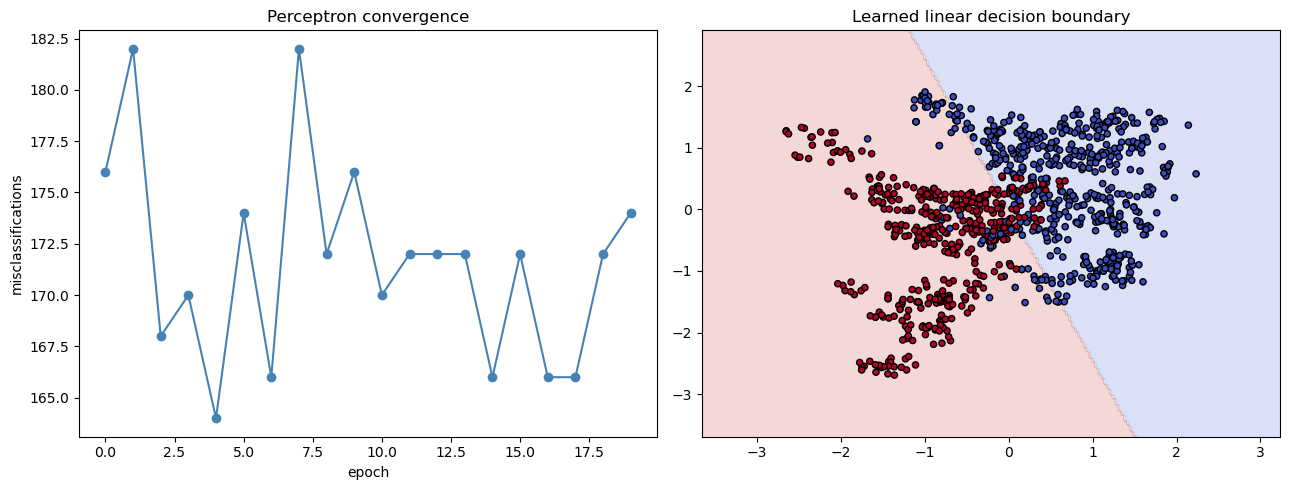

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(errors, marker="o", color="steelblue")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("misclassifications"); axes[0].set_title("Perceptron convergence")

xx, yy = np.meshgrid(np.linspace(X_train[:,0].min()-1, X_train[:,0].max()+1, 200),
                       np.linspace(X_train[:,1].min()-1, X_train[:,1].max()+1, 200))
Z = np.sign(weights[0]*xx + weights[1]*yy + bias)
axes[1].contourf(xx, yy, Z, alpha=0.2, cmap="coolwarm")
axes[1].scatter(X_train[:,0], X_train[:,1], c=y_train, cmap="coolwarm", edgecolor="k", s=20)
axes[1].set_title("Learned linear decision boundary")
plt.tight_layout(); plt.show()

## 2. Where a single perceptron fundamentally fails: XOR

In [4]:
xor_X = np.array([[0,0],[0,1],[1,0],[1,1]], dtype=float)
xor_y = np.array([-1, 1, 1, -1])  # XOR: true exactly when inputs DIFFER

xor_weights, xor_bias, xor_errors = train_perceptron(xor_X, xor_y, epochs=50, lr=0.1)
final_predictions = np.sign(xor_X @ xor_weights + xor_bias)
print(f"XOR targets:     {xor_y}")
print(f"perceptron predicts: {final_predictions.astype(int)}")
print(f"misclassifications never reach 0: {xor_errors[-10:]}")

XOR targets:     [-1  1  1 -1]
perceptron predicts: [0 0 0 0]
misclassifications never reach 0: [4, 4, 4, 4, 4, 4, 4, 4, 4, 4]


> ⚠️ **This isn't a tuning problem — no learning rate or epoch count fixes it.** XOR is not
> linearly separable: no single straight line separates the two classes. A perceptron can
> ONLY learn a linear decision boundary. This exact limitation (proven by Minsky & Papert in
> 1969) is what stalled neural network research for over a decade, and it's exactly what a
> HIDDEN LAYER fixes.

## 3. Activation functions: why the hidden layer needs nonlinearity

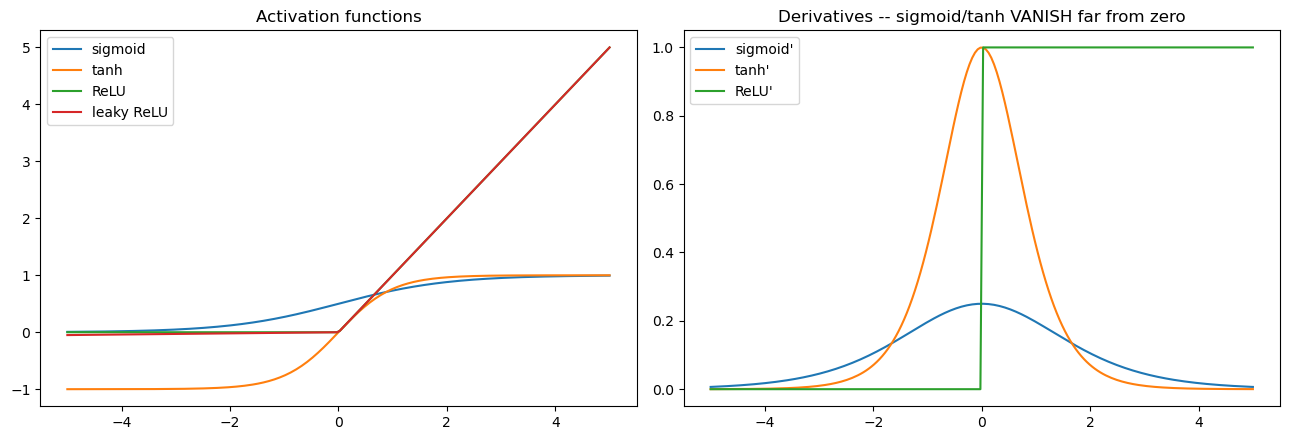

In [5]:
def sigmoid(x): return 1 / (1 + np.exp(-x))
def sigmoid_deriv(x): s = sigmoid(x); return s * (1 - s)
def tanh_deriv(x): return 1 - np.tanh(x)**2
def relu(x): return np.maximum(0, x)
def relu_deriv(x): return (x > 0).astype(float)
def leaky_relu(x, alpha=0.01): return np.where(x > 0, x, alpha * x)

x_range = np.linspace(-5, 5, 200)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(x_range, sigmoid(x_range), label="sigmoid")
axes[0].plot(x_range, np.tanh(x_range), label="tanh")
axes[0].plot(x_range, relu(x_range), label="ReLU")
axes[0].plot(x_range, leaky_relu(x_range), label="leaky ReLU")
axes[0].legend(); axes[0].set_title("Activation functions")

axes[1].plot(x_range, sigmoid_deriv(x_range), label="sigmoid'")
axes[1].plot(x_range, tanh_deriv(x_range), label="tanh'")
axes[1].plot(x_range, relu_deriv(x_range), label="ReLU'")
axes[1].legend(); axes[1].set_title("Derivatives -- sigmoid/tanh VANISH far from zero")
plt.tight_layout(); plt.show()

> 💡 **If every layer were linear (no activation function at all), stacking layers would
> collapse into a single linear transformation** — a 10-layer "deep" network with no
> nonlinearity is mathematically equivalent to ONE layer. The nonlinearity is what lets
> depth actually buy you anything. Notice also sigmoid/tanh's derivative approaching zero
> far from the origin — the **vanishing gradient problem** Section 9.2 addresses directly.

## 4. A full MLP with backpropagation, coded by hand

One hidden layer, sigmoid activation, binary cross-entropy loss. Every gradient below is
derived from the chain rule explicitly — this is precisely what `loss.backward()` automates
in PyTorch.

In [6]:
X_full = df[["variance", "skewness", "curtosis", "entropy"]].values
y_full = df["class"].values.reshape(-1, 1).astype(float)

X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(X_full, y_full, test_size=0.25, random_state=42)
scaler_f = StandardScaler().fit(X_train_f)
X_train_f, X_test_f = scaler_f.transform(X_train_f), scaler_f.transform(X_test_f)

class ManualMLP:
    def __init__(self, n_input, n_hidden, seed=42):
        rng = np.random.default_rng(seed)
        self.W1 = rng.normal(0, np.sqrt(1/n_input), (n_input, n_hidden))
        self.b1 = np.zeros((1, n_hidden))
        self.W2 = rng.normal(0, np.sqrt(1/n_hidden), (n_hidden, 1))
        self.b2 = np.zeros((1, 1))

    def forward(self, X):
        self.z1 = X @ self.W1 + self.b1
        self.a1 = sigmoid(self.z1)
        self.z2 = self.a1 @ self.W2 + self.b2
        self.a2 = sigmoid(self.z2)  # final prediction (probability)
        return self.a2

    def backward(self, X, y, lr):
        n = X.shape[0]
        # binary cross-entropy loss gradient w.r.t. z2 simplifies beautifully to (a2 - y)
        dz2 = self.a2 - y
        dW2 = self.a1.T @ dz2 / n
        db2 = dz2.mean(axis=0, keepdims=True)

        da1 = dz2 @ self.W2.T
        dz1 = da1 * sigmoid_deriv(self.z1)   # chain rule through the hidden activation
        dW1 = X.T @ dz1 / n
        db1 = dz1.mean(axis=0, keepdims=True)

        self.W2 -= lr * dW2; self.b2 -= lr * db2
        self.W1 -= lr * dW1; self.b1 -= lr * db1

def bce_loss(y_true, y_pred, eps=1e-8):
    return -np.mean(y_true * np.log(y_pred + eps) + (1 - y_true) * np.log(1 - y_pred + eps))

mlp = ManualMLP(n_input=4, n_hidden=8)
loss_history = []
for epoch in range(500):
    pred = mlp.forward(X_train_f)
    loss = bce_loss(y_train_f, pred)
    loss_history.append(loss)
    mlp.backward(X_train_f, y_train_f, lr=0.5)

print(f"final train loss: {loss_history[-1]:.4f}")

final train loss: 0.0386


test accuracy: 98.54%


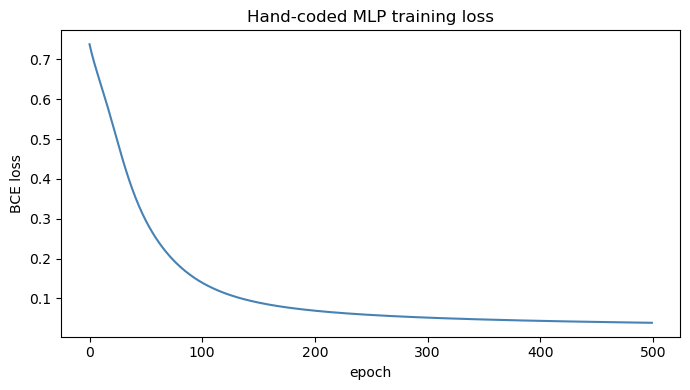

In [7]:
test_pred = mlp.forward(X_test_f)
test_accuracy = ((test_pred > 0.5).astype(int) == y_test_f).mean()
print(f"test accuracy: {test_accuracy:.2%}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(loss_history, color="steelblue")
ax.set_xlabel("epoch"); ax.set_ylabel("BCE loss"); ax.set_title("Hand-coded MLP training loss")
plt.tight_layout(); plt.show()

## 5. Verifying the hand-coded backprop against PyTorch's autograd

The real test of "do I understand backpropagation" isn't the accuracy number — it's
whether the GRADIENTS themselves match what autograd computes independently. If they agree
to several decimal places, the by-hand chain rule derivation above is provably correct, not
just "happens to train."

In [8]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import torch
import torch.nn as nn

torch.manual_seed(0)
X_t = torch.tensor(X_train_f, dtype=torch.float32)
y_t = torch.tensor(y_train_f, dtype=torch.float32)

torch_mlp = nn.Sequential(nn.Linear(4, 8), nn.Sigmoid(), nn.Linear(8, 1), nn.Sigmoid())

# a fresh manual MLP, so both start from IDENTICAL initial weights -- required for a fair gradient check
mlp2 = ManualMLP(n_input=4, n_hidden=8)
with torch.no_grad():
    torch_mlp[0].weight.copy_(torch.tensor(mlp2.W1.T, dtype=torch.float32))
    torch_mlp[0].bias.copy_(torch.tensor(mlp2.b1.flatten(), dtype=torch.float32))
    torch_mlp[2].weight.copy_(torch.tensor(mlp2.W2.T, dtype=torch.float32))
    torch_mlp[2].bias.copy_(torch.tensor(mlp2.b2.flatten(), dtype=torch.float32))

# one manual forward+backward pass
manual_pred = mlp2.forward(X_train_f)
manual_loss = bce_loss(y_train_f, manual_pred)
mlp2.backward(X_train_f, y_train_f, lr=0.0)  # lr=0: compute gradients without updating, for comparison
manual_dW2 = (mlp2.a1.T @ (mlp2.a2 - y_train_f)) / X_train_f.shape[0]

# one PyTorch forward+backward pass
torch_pred = torch_mlp(X_t)
torch_loss = nn.functional.binary_cross_entropy(torch_pred, y_t)
torch_mlp.zero_grad()
torch_loss.backward()
torch_dW2 = torch_mlp[2].weight.grad.numpy()

print(f"manual BCE loss:  {manual_loss:.6f}")
print(f"PyTorch BCE loss: {torch_loss.item():.6f}")
print(f"\nmax abs difference in output-layer weight gradients: {np.abs(manual_dW2.T - torch_dW2).max():.8f}")

manual BCE loss:  0.738230
PyTorch BCE loss: 0.738230

max abs difference in output-layer weight gradients: 0.00000001


> 💡 **A near-zero gradient difference is the whole point of this exercise.** It proves the
> hand-derived chain rule above and PyTorch's autograd are computing the EXACT same thing —
> autograd isn't a different algorithm, it's the same calculus, automated.

## 🎯 Exercises

1. Run the perceptron on the FULL 4-feature banknote data (`variance, skewness, curtosis,
   entropy`) instead of just 2 — does it converge to 0 misclassifications? What does that
   tell you about whether the full dataset is linearly separable?
2. Add a hidden layer to solve XOR: implement a tiny 2-input, 2-hidden-unit, 1-output MLP
   with sigmoid activations and manual backprop, and confirm it converges where the
   perceptron couldn't.
3. Swap `sigmoid` for `relu` in `ManualMLP`'s hidden layer (you'll need `relu_deriv` in the
   backward pass) — does training converge faster?
4. Compute MSE loss on the same predictions instead of BCE loss — plot both loss curves
   over training. Which one produces larger gradients when a prediction is confidently
   WRONG (e.g., predicting 0.01 when the true label is 1)?

### Solutions

```python
# 1.
w4, b4, err4 = train_perceptron(X_train_f, np.where(y_train_f.flatten()==1, 1, -1), epochs=50)
print(err4[-5:])

# 2.
xor_mlp = ManualMLP(n_input=2, n_hidden=2)
xor_y_binary = np.array([[0],[1],[1],[0]], dtype=float)
for _ in range(2000):
    xor_mlp.forward(xor_X)
    xor_mlp.backward(xor_X, xor_y_binary, lr=1.0)
print(xor_mlp.forward(xor_X))

# 3.
class ManualMLPRelu(ManualMLP):
    def forward(self, X):
        self.z1 = X @ self.W1 + self.b1
        self.a1 = relu(self.z1)
        self.z2 = self.a1 @ self.W2 + self.b2
        self.a2 = sigmoid(self.z2)
        return self.a2
    def backward(self, X, y, lr):
        n = X.shape[0]
        dz2 = self.a2 - y
        dW2 = self.a1.T @ dz2 / n
        db2 = dz2.mean(axis=0, keepdims=True)
        da1 = dz2 @ self.W2.T
        dz1 = da1 * relu_deriv(self.z1)
        dW1 = X.T @ dz1 / n
        db1 = dz1.mean(axis=0, keepdims=True)
        self.W2 -= lr*dW2; self.b2 -= lr*db2; self.W1 -= lr*dW1; self.b1 -= lr*db1

# 4.
mse = np.mean((y_train_f - manual_pred)**2)
print(mse, manual_loss)
```